In [1]:
import os, time, math, copy, random, json
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
import pandas as pd

QUICK = False          # True -> tiny subset + few epochs, just to check that everything runs

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'
print('device:', device, '| torch', torch.__version__, '| AMP:', USE_AMP)
if device.type == 'cuda':
    print(torch.cuda.get_device_name(0))

def seed_all(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_all(0)
torch.backends.cudnn.benchmark = True

# ---- experiment sizes (full vs quick) --------------------------------------
CFG = dict(
    n_train   = 45_000 if not QUICK else 2_000,
    n_val     = 5_000  if not QUICK else 1_000,
    ep_t1     = 10 if not QUICK else 1,     # Task 1c MLP epochs
    ep_t2     = 8  if not QUICK else 1,     # Task 2c epochs per (optimizer, lr)
    ep_t3a    = 30 if not QUICK else 1,     # Task 3a epochs (5k subset)
    n_t3a     = 5_000 if not QUICK else 1_000,
    ep_t3b    = 20 if not QUICK else 1,     # Task 3b epochs per network
    depths_3b = [8, 20, 56] if not QUICK else [8, 20],
    ep_t4     = 20 if not QUICK else 1,     # Task 4 (hard limit 20)
    bs        = 128,
)
print(json.dumps(CFG, indent=1))

device: cuda | torch 2.11.0+cu130 | AMP: True
Tesla T4
{
 "n_train": 45000,
 "n_val": 5000,
 "ep_t1": 10,
 "ep_t2": 8,
 "ep_t3a": 30,
 "n_t3a": 5000,
 "ep_t3b": 20,
 "depths_3b": [
  8,
  20,
  56
 ],
 "ep_t4": 20,
 "bs": 128
}


100%|██████████| 170M/170M [46:18<00:00, 61.4kB/s]


train (45000, 3, 32, 32) val (5000, 3, 32, 32)
channel mean [0.4912 0.482  0.4464] std [0.2472 0.2436 0.2617]


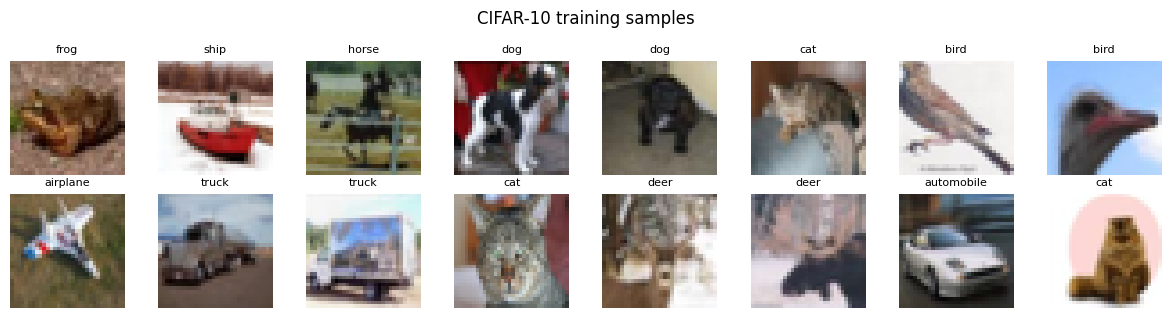

In [2]:
root = './data'
full_train = torchvision.datasets.CIFAR10(root, train=True, download=True)
X_all = torch.from_numpy(np.asarray(full_train.data)).permute(0, 3, 1, 2).contiguous()   # (50000,3,32,32) uint8
y_all = torch.tensor(full_train.targets, dtype=torch.long)
CLASSES = full_train.classes

# fixed, seeded 45k / 5k split
g = torch.Generator().manual_seed(0)
perm = torch.randperm(len(X_all), generator=g)
tr_idx, va_idx = perm[:45_000], perm[45_000:50_000]
tr_idx, va_idx = tr_idx[:CFG['n_train']], va_idx[:CFG['n_val']]

X_tr, y_tr = X_all[tr_idx], y_all[tr_idx]
X_va, y_va = X_all[va_idx], y_all[va_idx]

# per-channel mean / std from the TRAINING split only
MEAN = X_tr.float().div(255).mean(dim=(0, 2, 3))
STD  = X_tr.float().div(255).std(dim=(0, 2, 3))
print('train', tuple(X_tr.shape), 'val', tuple(X_va.shape))
print('channel mean', MEAN.numpy().round(4), 'std', STD.numpy().round(4))

X_tr, y_tr, X_va, y_va = X_tr.to(device), y_tr.to(device), X_va.to(device), y_va.to(device)
MEAN_D, STD_D = MEAN.to(device).view(1, 3, 1, 1), STD.to(device).view(1, 3, 1, 1)

def normalize(x_uint8):
    return (x_uint8.float().div_(255) - MEAN_D) / STD_D

class GPULoader:
    '''Iterates over (x, y) mini-batches that already live on the GPU.
    aug: optional function applied to the normalised float batch.'''
    def __init__(self, X, y, bs, shuffle=True, aug=None, drop_last=False):
        self.X, self.y, self.bs, self.shuffle, self.aug, self.drop_last = X, y, bs, shuffle, aug, drop_last
    def __len__(self):
        n = len(self.X)
        return n // self.bs if self.drop_last else math.ceil(n / self.bs)
    def __iter__(self):
        n = len(self.X)
        idx = torch.randperm(n, device=self.X.device) if self.shuffle else torch.arange(n, device=self.X.device)
        for i in range(0, n - (n % self.bs if self.drop_last else 0), self.bs):
            b = idx[i:i + self.bs]
            x = normalize(self.X[b])
            if self.aug is not None:
                x = self.aug(x)
            yield x, self.y[b]

# a quick look at the data
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_tr[i].permute(1, 2, 0).cpu().numpy()); ax.set_title(CLASSES[y_tr[i]], fontsize=8); ax.axis('off')
plt.suptitle('CIFAR-10 training samples'); plt.tight_layout(); plt.show()

In [4]:
class Linear:
    def __init__(self, in_features, out_features):
        self.W = torch.randn(in_features, out_features, device=device) * (2 / in_features) ** 0.5
        self.b = torch.zeros(out_features, device=device)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, grad):
        self.dW = self.x.T @ grad
        self.db = grad.sum(dim=0)
        return grad @ self.W.T


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x.clamp(min=0)

    def backward(self, grad):
        return grad * self.mask


def softmax_cross_entropy(logits, targets):
    # Numerically stable softmax
    shifted = logits - logits.max(dim=1, keepdim=True).values
    exp_scores = shifted.exp()
    probs = exp_scores / exp_scores.sum(dim=1, keepdim=True)

    n = logits.shape[0]
    loss = -torch.log(
        probs[torch.arange(n, device=device), targets] + 1e-12
    ).mean()

    grad = probs.clone()
    grad[torch.arange(n, device=device), targets] -= 1
    grad /= n

    return loss, grad

In [5]:
class MLP:
    def __init__(self, input_size=3072, hidden_size=256, num_classes=10):
        self.fc1 = Linear(input_size, hidden_size)
        self.relu = ReLU()
        self.fc2 = Linear(hidden_size, num_classes)

    def forward(self, x):
        x = x.flatten(start_dim=1)
        x = self.fc1.forward(x)
        x = self.relu.forward(x)
        return self.fc2.forward(x)

    def backward(self, grad):
        grad = self.fc2.backward(grad)
        grad = self.relu.backward(grad)
        self.fc1.backward(grad)

    def parameters(self):
        return [
            (self.fc1.W, self.fc1.dW),
            (self.fc1.b, self.fc1.db),
            (self.fc2.W, self.fc2.dW),
            (self.fc2.b, self.fc2.db),
        ]

In [6]:
model = MLP().to(device) if False else MLP()

x, y = next(iter(GPULoader(X_tr, y_tr, bs=64, shuffle=True)))

logits = model.forward(x)
loss, grad = softmax_cross_entropy(logits, y)
model.backward(grad)

print("Logits shape:", logits.shape)
print("Loss:", loss.item())
print("Weight gradient shape:", model.fc1.dW.shape)

Logits shape: torch.Size([64, 10])
Loss: 3.459329605102539
Weight gradient shape: torch.Size([3072, 256])


In [7]:
import torch.nn.functional as F

# Use a small batch for verification
x_test, y_test = x[:8], y[:8]

# 1. Manual gradients
logits = model.forward(x_test)
loss_manual, grad = softmax_cross_entropy(logits, y_test)
model.backward(grad)

manual_grads = [
    model.fc1.dW.clone(), model.fc1.db.clone(),
    model.fc2.dW.clone(), model.fc2.db.clone()
]

# 2. Autograd reference
W1 = model.fc1.W.detach().clone().requires_grad_(True)
b1 = model.fc1.b.detach().clone().requires_grad_(True)
W2 = model.fc2.W.detach().clone().requires_grad_(True)
b2 = model.fc2.b.detach().clone().requires_grad_(True)

z1 = x_test.flatten(1) @ W1 + b1
h1 = z1.relu()
logits_ref = h1 @ W2 + b2
loss_ref = F.cross_entropy(logits_ref, y_test)
loss_ref.backward()

auto_grads = [W1.grad, b1.grad, W2.grad, b2.grad]

# Relative errors and allclose checks
for name, gm, ga in zip(
    ["W1", "b1", "W2", "b2"], manual_grads, auto_grads
):
    rel_error = (gm - ga).norm() / (ga.norm() + 1e-12)
    print(name, "relative error:", rel_error.item(),
          "| allclose:", torch.allclose(gm, ga, rtol=1e-4, atol=1e-6))

W1 relative error: 6.202941449373611e-08 | allclose: True
b1 relative error: 6.82342431446159e-08 | allclose: True
W2 relative error: 3.837935480532906e-08 | allclose: True
b2 relative error: 2.620320316282232e-08 | allclose: True


In [8]:
def loss_at(W1, b1, W2, b2):
    logits = (x_test.flatten(1) @ W1 + b1).relu() @ W2 + b2
    return F.cross_entropy(logits, y_test)

eps = 1e-3

checks = [
    (model.fc1.W, model.fc1.dW, (0, 0)),
    (model.fc1.b, model.fc1.db, (0,)),
    (model.fc2.W, model.fc2.dW, (0, 0)),
    (model.fc2.b, model.fc2.db, (0,))
]

for i, (param, grad_manual, idx) in enumerate(checks):
    original = param[idx].item()

    with torch.no_grad():
        param[idx] = original + eps
    plus = loss_at(model.fc1.W, model.fc1.b,
                   model.fc2.W, model.fc2.b).item()

    with torch.no_grad():
        param[idx] = original - eps
    minus = loss_at(model.fc1.W, model.fc1.b,
                    model.fc2.W, model.fc2.b).item()

    with torch.no_grad():
        param[idx] = original

    numerical = (plus - minus) / (2 * eps)
    analytical = grad_manual[idx].item()
    rel_error = abs(numerical - analytical) / (
        abs(numerical) + abs(analytical) + 1e-12
    )

    print(f"Parameter {i}: manual={analytical:.6g}, "
          f"finite difference={numerical:.6g}, "
          f"relative error={rel_error:.3e}")

Parameter 0: manual=-0.0297775, finite difference=-0.0298023, relative error=4.160e-04
Parameter 1: manual=0.00398612, finite difference=0.00405312, relative error=8.334e-03
Parameter 2: manual=0.00376479, finite difference=0.00393391, relative error=2.197e-02
Parameter 3: manual=0.0607057, finite difference=0.0609159, relative error=1.728e-03


In [13]:
EPOCHS = 50
BATCH_SIZE = 256
LR = 0.01

history = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": []
}

for epoch in range(EPOCHS):
    total_loss, correct, total = 0.0, 0, 0

    for xb, yb in GPULoader(X_tr, y_tr, BATCH_SIZE, shuffle=True):
        logits = model.forward(xb)
        loss, grad = softmax_cross_entropy(logits, yb)
        model.backward(grad)

        with torch.no_grad():
            for param, g in model.parameters():
                param -= LR * g

        total_loss += loss.item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
        total += len(yb)

    history["train_loss"].append(total_loss / total)
    history["train_acc"].append(100 * correct / total)

    # Validation: no weight updates
    val_loss_sum, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for xb, yb in GPULoader(X_va, y_va, BATCH_SIZE, shuffle=False):
            logits = model.forward(xb)
            loss, _ = softmax_cross_entropy(logits, yb)

            val_loss_sum += loss.item() * len(yb)
            val_correct += (logits.argmax(1) == yb).sum().item()
            val_total += len(yb)

    history["val_loss"].append(val_loss_sum / val_total)
    history["val_acc"].append(100 * val_correct / val_total)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train loss: {history['train_loss'][-1]:.4f} | "
        f"Val loss: {history['val_loss'][-1]:.4f} | "
        f"Train acc: {history['train_acc'][-1]:.2f}% | "
        f"Val acc: {history['val_acc'][-1]:.2f}%"
    )

Epoch 01/50 | Train loss: 0.8425 | Val loss: 1.4912 | Train acc: 72.83% | Val acc: 50.74%
Epoch 02/50 | Train loss: 0.8315 | Val loss: 1.4861 | Train acc: 73.30% | Val acc: 51.02%
Epoch 03/50 | Train loss: 0.8248 | Val loss: 1.4805 | Train acc: 73.50% | Val acc: 51.44%
Epoch 04/50 | Train loss: 0.8139 | Val loss: 1.4868 | Train acc: 74.00% | Val acc: 51.18%
Epoch 05/50 | Train loss: 0.8067 | Val loss: 1.4980 | Train acc: 74.22% | Val acc: 50.84%
Epoch 06/50 | Train loss: 0.7989 | Val loss: 1.4868 | Train acc: 74.63% | Val acc: 51.58%
Epoch 07/50 | Train loss: 0.7897 | Val loss: 1.4971 | Train acc: 75.00% | Val acc: 50.70%
Epoch 08/50 | Train loss: 0.7827 | Val loss: 1.5014 | Train acc: 75.18% | Val acc: 50.92%
Epoch 09/50 | Train loss: 0.7742 | Val loss: 1.5167 | Train acc: 75.50% | Val acc: 50.28%
Epoch 10/50 | Train loss: 0.7673 | Val loss: 1.5080 | Train acc: 75.84% | Val acc: 51.26%
Epoch 11/50 | Train loss: 0.7588 | Val loss: 1.5203 | Train acc: 76.23% | Val acc: 51.04%
Epoch 12/5

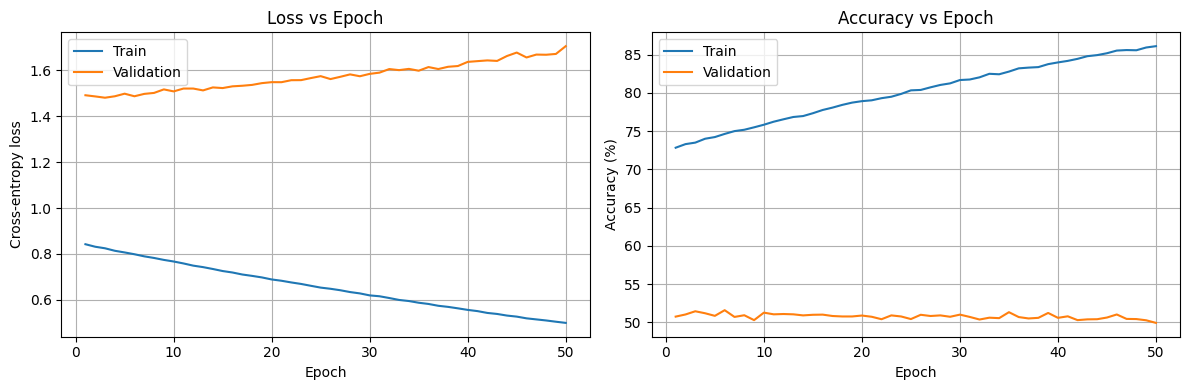

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = range(1, EPOCHS + 1)

axes[0].plot(epochs, history["train_loss"], label="Train")
axes[0].plot(epochs, history["val_loss"], label="Validation")
axes[0].set_title("Loss vs Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, history["train_acc"], label="Train")
axes[1].plot(epochs, history["val_acc"], label="Validation")
axes[1].set_title("Accuracy vs Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [12]:
correct, total = 0, 0

with torch.no_grad():
    for xb, yb in GPULoader(X_va, y_va, BATCH_SIZE, shuffle=False):
        logits = model.forward(xb)
        predictions = logits.argmax(dim=1)
        correct += (predictions == yb).sum().item()
        total += len(yb)

val_accuracy = 100 * correct / total
print(f"Validation accuracy: {val_accuracy:.2f}%")

Validation accuracy: 51.36%
